# 04 · Predicción de los próximos lanzamientos

**Entrada:** `models/final_model.pkl`, `data/processed/upcoming_processed.csv`, `data/test/test.csv`
**Salida:** `data/processed/upcoming_predictions.csv`

Aplicamos el modelo final a los juegos que todavía no han salido.

Las probabilidades de modelos entrenados con `class_weight`/`scale_pos_weight` están **infladas** (no son probabilidades reales). Para traducirlas a algo interpretable usamos el **test**: para cada juego próximo miramos en qué **decil** de puntuación caería y qué % de juegos de ese decil fueron realmente exitosos.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
PROC, TEST_DIR, MODELS = Path("../data/processed"), Path("../data/test"), Path("../models")

model = joblib.load(MODELS / "final_model.pkl")
with open(MODELS / "final_model_meta.json", encoding="utf-8") as f:
    meta = json.load(f)
FEATURES, THR = meta["features"], meta["umbral"]
print("Modelo:", meta["modelo"], "| umbral:", round(THR, 3))

up = pd.read_csv(PROC / "upcoming_processed.csv")
test = pd.read_csv(TEST_DIR / "test.csv")
print("Próximos lanzamientos:", len(up))

Modelo: xgboost | umbral: 0.774
Próximos lanzamientos: 36


## 1. Calidad de los datos de entrada

In [2]:
faltan = up[["price", "release_month"]].isna().sum()
print("Juegos sin precio anunciado (se imputa la mediana):", faltan["price"])
print("Juegos sin fecha exacta (mes imputado):", faltan["release_month"])
print("Juegos de estudios debutantes (dev_prev_games = 0):", (up["dev_prev_games"] == 0).sum())
print("Juegos sin logros publicados (se imputa la mediana):", up["achievements"].isna().sum())

Juegos sin precio anunciado (se imputa la mediana): 27
Juegos sin fecha exacta (mes imputado): 1
Juegos de estudios debutantes (dev_prev_games = 0): 22
Juegos sin logros publicados (se imputa la mediana): 29


## 2. Calibración con el test: puntuación → % de éxito real

In [3]:
test["proba"] = model.predict_proba(test[FEATURES])[:, 1]
test["decil"] = pd.qcut(test["proba"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)

tabla_deciles = test.groupby("decil").agg(proba_min=("proba", "min"), proba_max=("proba", "max"),
                                          pct_exito_real=("exitoso", "mean"))
tabla_deciles["pct_exito_real"] *= 100
BASE = test["exitoso"].mean() * 100
tabla_deciles.round(3)

C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_20204\4049119869.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test["proba"] = model.predict_proba(test[FEATURES])[:, 1]
C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_20204\4049119869.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test["decil"] = pd.qcut(test["proba"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)


,proba_min,proba_max,pct_exito_real
decil,,,
1,0.757,0.991,42.112
2,0.504,0.757,15.967
3,0.318,0.504,6.997
4,0.211,0.318,3.053
5,0.145,0.211,1.463
6,0.102,0.144,0.764
7,0.071,0.102,0.700
8,0.047,0.071,0.445
9,0.027,0.047,0.127


In [4]:
# Límite inferior de cada decil (de mejor a peor) para asignar decil a un juego nuevo
cortes = tabla_deciles["proba_min"].values


def asignar_decil(p):
    for d, c in enumerate(cortes, 1):
        if p >= c:
            return d
    return 10

## 3. Predicción

In [5]:
up["proba"] = model.predict_proba(up[FEATURES])[:, 1]
up["prediccion"] = np.where(up["proba"] >= THR, "Exitoso", "No exitoso")
up["decil"] = up["proba"].map(asignar_decil)
up["pct_exito_esperado"] = up["decil"].map(tabla_deciles["pct_exito_real"]).round(1)
up["vs_media"] = (up["pct_exito_esperado"] / BASE).round(1)


def nivel(d):
    return "🟢 Alto" if d <= 2 else ("🟡 Medio" if d <= 5 else "🔴 Bajo")


up["potencial"] = up["decil"].map(nivel)

ranking = (up.sort_values("proba", ascending=False)
             [["name", "release_date", "price", "dev_prev_games", "dev_prev_hits",
               "proba", "decil", "pct_exito_esperado", "vs_media", "potencial", "prediccion"]]
             .reset_index(drop=True))
ranking.index += 1
ranking

C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_20204\3651586916.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  up["proba"] = model.predict_proba(up[FEATURES])[:, 1]
C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_20204\3651586916.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  up["prediccion"] = np.where(up["proba"] >= THR, "Exitoso", "No exitoso")
C:\Users\TB Val 13\AppData\Local\Temp\ipykernel_20204\3651586916.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

,name,release_date,price,dev_prev_games,dev_prev_hits,proba,decil,pct_exito_esperado,vs_media,potencial,prediccion
1,Arctic Drive,2026-11-25,19.99,1,0,0.908544,1,42.1,5.9,🟢 Alto,Exitoso
2,Reshine,2026-11-26,NaN,1,1,0.906472,1,42.1,5.9,🟢 Alto,Exitoso
3,No Asteroids,2026-11-24,7.99,0,0,0.884875,1,42.1,5.9,🟢 Alto,Exitoso
4,"Warhammer 40,000: Dawn of War IV",2026-12-03,59.99,9,2,0.845630,1,42.1,5.9,🟢 Alto,Exitoso
5,Drunken Goddess Reflux,2026-12-08,NaN,4,1,0.838544,1,42.1,5.9,🟢 Alto,Exitoso
6,Blind Descent,2026-12-02,NaN,0,0,0.811586,1,42.1,5.9,🟢 Alto,Exitoso
7,Dumpster Gang,2026-12-03,NaN,0,0,0.808101,1,42.1,5.9,🟢 Alto,Exitoso
8,Me and You,2026-11-25,NaN,1,0,0.806611,1,42.1,5.9,🟢 Alto,Exitoso
9,Shark Mart,2026-11-26,NaN,2,0,0.779622,1,42.1,5.9,🟢 Alto,Exitoso
10,SHRED A BILLION,2026-11-24,6.99,0,0,0.731873,2,16.0,2.2,🟢 Alto,No exitoso


### 3.1 ¿Por qué hay tantos juegos con potencial alto?
Comprobamos dónde coloca el modelo a los juegos **históricos** con un perfil parecido a los próximos lanzamientos (≥ 5 idiomas, ≥ 10 capturas y al menos un vídeo) y qué % de ellos triunfó realmente.

In [6]:
similares = test[(test["n_languages"] >= 5) & (test["n_screenshots"] >= 10) & (test["n_movies"] >= 1)]
print(f"Juegos históricos con perfil parecido a los próximos: {len(similares):,} "
      f"({len(similares)/len(test)*100:.0f}% del test)")
print(f"% en deciles 1-2: {(similares['decil'] <= 2).mean()*100:.0f}%  (en todo el test: 20%)")
print(f"% de éxito real:  {similares['exitoso'].mean()*100:.1f}%  (en todo el test: {BASE:.1f}%)")

Juegos históricos con perfil parecido a los próximos: 712 (5% del test)
% en deciles 1-2: 77%  (en todo el test: 20%)
% de éxito real:  29.1%  (en todo el test: 7.2%)


In [7]:
print(up["potencial"].value_counts())
print(f"\nTasa base histórica de éxito: {BASE:.1f}%")

potencial
🟢 Alto     20
🟡 Medio    15
🔴 Bajo      1
Name: count, dtype: int64

Tasa base histórica de éxito: 7.2%


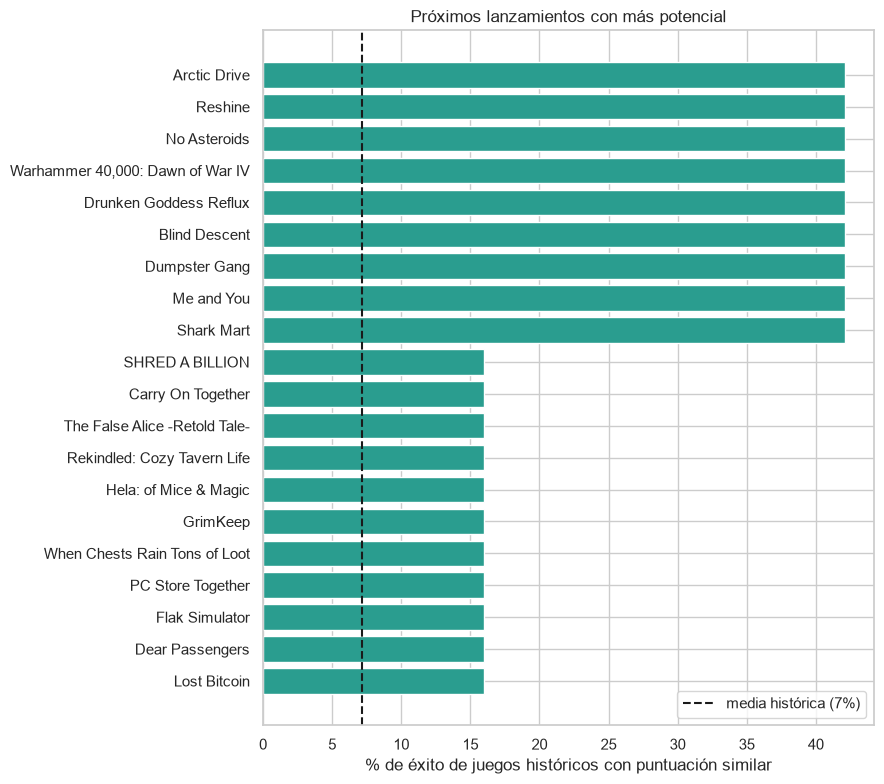

In [8]:
top = ranking.head(20).iloc[::-1]
colores = top["potencial"].map({"🟢 Alto": "#2a9d8f", "🟡 Medio": "#e9c46a", "🔴 Bajo": "#e76f51"})
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top["name"], top["pct_exito_esperado"], color=colores)
ax.axvline(BASE, color="k", ls="--", label=f"media histórica ({BASE:.0f}%)")
ax.set_xlabel("% de éxito de juegos históricos con puntuación similar")
ax.set_title("Próximos lanzamientos con más potencial"); ax.legend()
plt.tight_layout(); plt.show()

## 4. ¿Por qué el modelo cree en el juego nº 1? (SHAP, opcional)

c:\Users\TB Val 13\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Juego: Arctic Drive


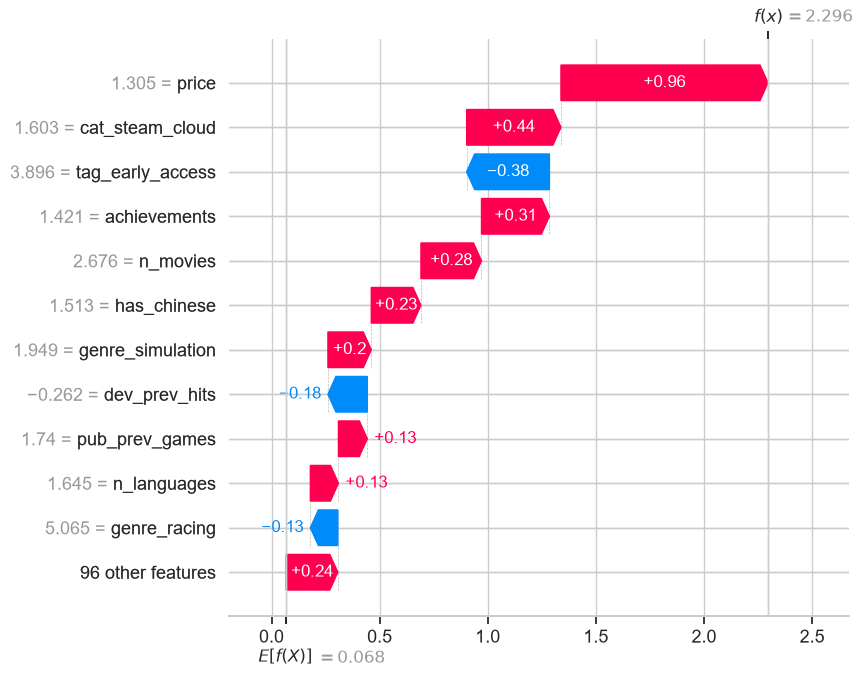

In [9]:
try:
    import shap
    prep, clf = model.named_steps["prep"], model.named_steps["clf"]
    mejor = up.sort_values("proba", ascending=False).head(1)
    Xm = prep.transform(mejor[FEATURES])
    explainer = shap.TreeExplainer(clf)
    sv = explainer(pd.DataFrame(Xm, columns=prep.get_feature_names_out()))
    print("Juego:", mejor["name"].iloc[0])
    shap.plots.waterfall(sv[0], max_display=12)
except Exception as e:
    print("SHAP no disponible:", e)

In [10]:
# Sensibilidad al precio para los juegos sin precio anunciado
precios = [0.0, 4.99, 9.99, 19.99, 29.99, 59.99]
sin_precio = up[up["price"].isna()]
sens = {}
for p in precios:
    Xp = sin_precio[FEATURES].copy()
    Xp["price"] = p
    Xp["is_free"] = int(p == 0)
    sens[f"${p:g}"] = [asignar_decil(v) for v in model.predict_proba(Xp)[:, 1]]

sens = pd.DataFrame(sens, index=sin_precio["name"])
sens["decil_actual"] = sin_precio["decil"].values
sens["rango_deciles"] = sens[[f"${p:g}" for p in precios]].max(axis=1) - sens[[f"${p:g}" for p in precios]].min(axis=1)
print("Decil según el precio (1 = mejor). rango_deciles = cuánto se mueve:")
sens.sort_values("decil_actual")

Decil según el precio (1 = mejor). rango_deciles = cuánto se mueve:


,$0,$4.99,$9.99,$19.99,$29.99,$59.99,decil_actual,rango_deciles
name,,,,,,,,
Dumpster Gang,1,1,1,1,1,1,1,0
Reshine,1,1,1,1,1,1,1,0
Drunken Goddess Reflux,1,1,1,1,1,1,1,0
Shark Mart,1,1,1,1,1,1,1,0
Me and You,1,1,1,1,1,1,1,0
Blind Descent,1,1,1,1,1,1,1,0
Lost Bitcoin,2,2,2,2,2,2,2,0
Flak Simulator,2,2,2,1,1,1,2,1
GrimKeep,2,2,2,2,2,2,2,0


## 5. Guardado

In [11]:
up.sort_values("proba", ascending=False).to_csv(PROC / "upcoming_predictions.csv", index=False)
print("Guardado data/processed/upcoming_predictions.csv")

Guardado data/processed/upcoming_predictions.csv


## 6. Conclusiones

*(Rellenar tras ejecutar)*

- Nº de juegos con potencial alto / medio / bajo: …
- Juegos más prometedores y por qué: …
- Advertencias: muestra pequeña de próximos lanzamientos, precio o fecha sin anunciar en algunos, estudios debutantes.